# **Life Expectancy Prediction**

In [156]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor, StackingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold

import statsmodels.api as sm
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    PoissonRegressor,
    GammaRegressor,
    TweedieRegressor
)


In [157]:
df = pd.read_csv("Life Expectancy Data.csv")

df.columns = df.columns.str.strip()
df = df.replace(["?", "", "NA", "N/A"], np.nan)

df = df.drop(columns=["Country"], errors="ignore")

for col in df.columns:
    if col != "Status":
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Life expectancy"])

df.head()

,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [158]:
print(df.shape)

(2928, 21)


In [159]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2928 entries, 0 to 2937
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Year                             2928 non-null   int64  
 1   Status                           2928 non-null   object 
 2   Life expectancy                  2928 non-null   float64
 3   Adult Mortality                  2928 non-null   float64
 4   infant deaths                    2928 non-null   int64  
 5   Alcohol                          2735 non-null   float64
 6   percentage expenditure           2928 non-null   float64
 7   Hepatitis B                      2375 non-null   float64
 8   Measles                          2928 non-null   int64  
 9   BMI                              2896 non-null   float64
 10  under-five deaths                2928 non-null   int64  
 11  Polio                            2909 non-null   float64
 12  Total expenditure        

In [160]:
df.isnull().sum()

,0
Year,0
Status,0
Life expectancy,0
Adult Mortality,0
infant deaths,0
Alcohol,193
percentage expenditure,0
Hepatitis B,553
Measles,0
BMI,32


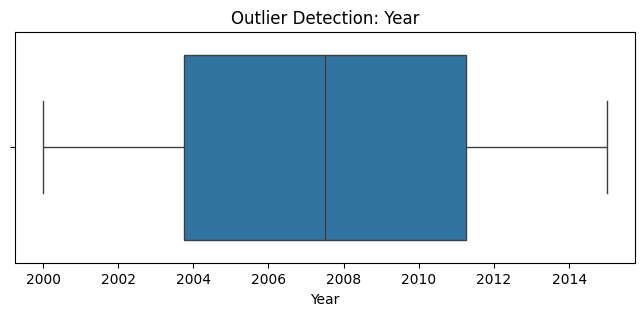

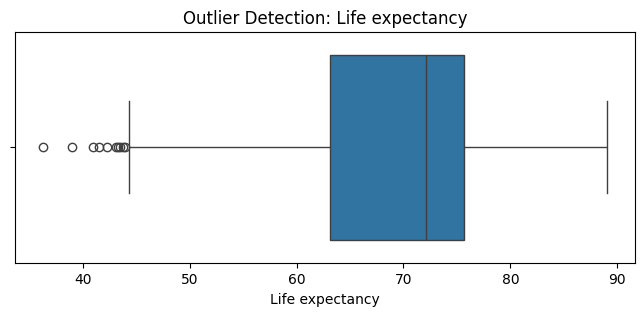

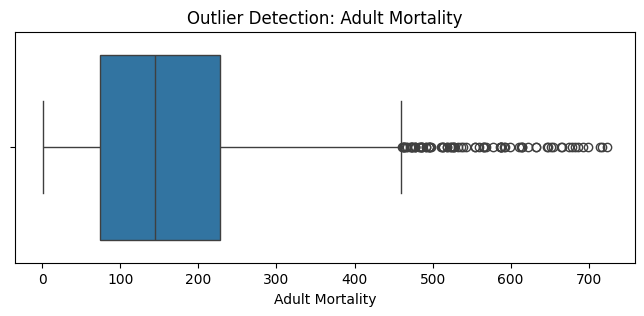

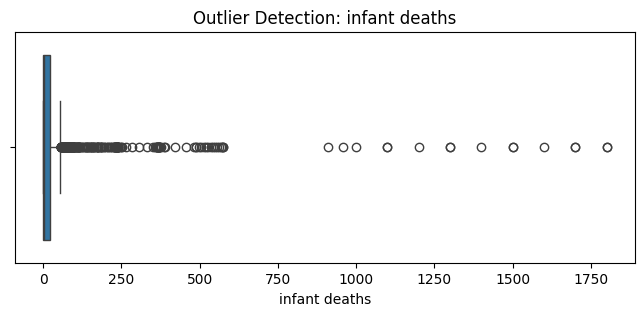

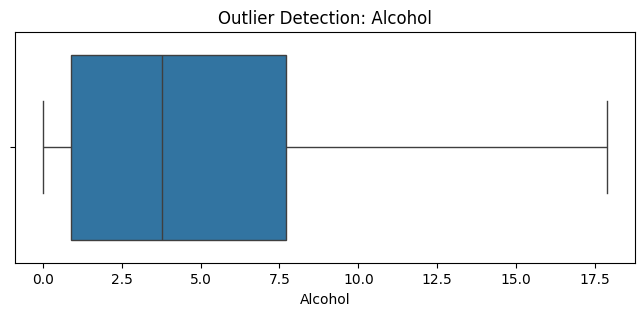

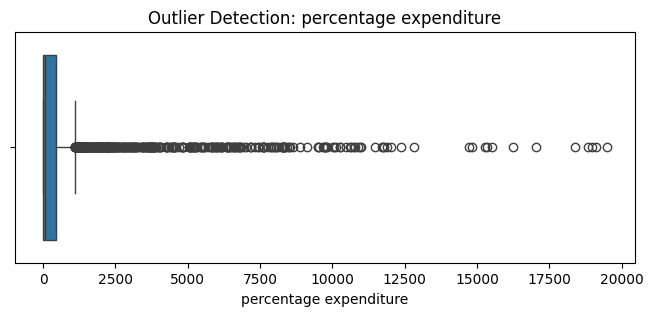

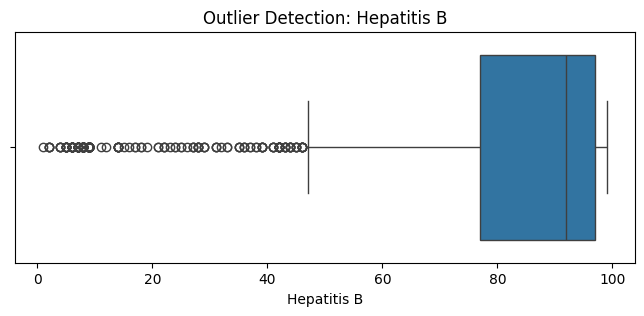

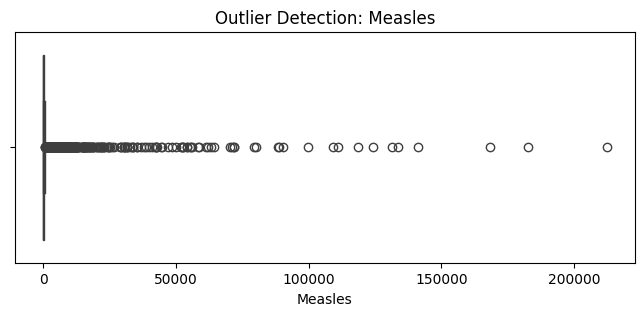

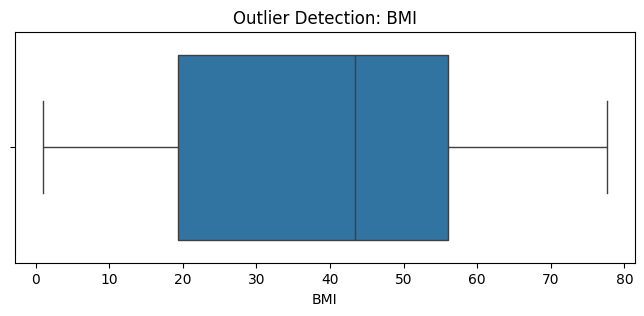

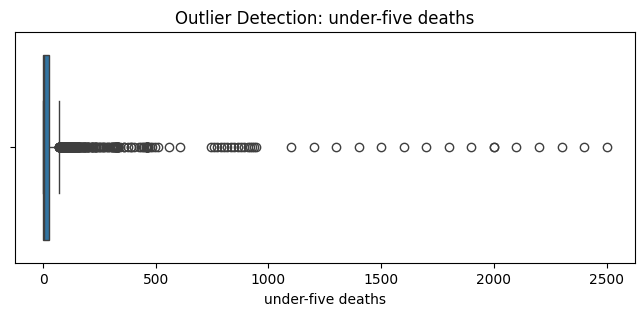

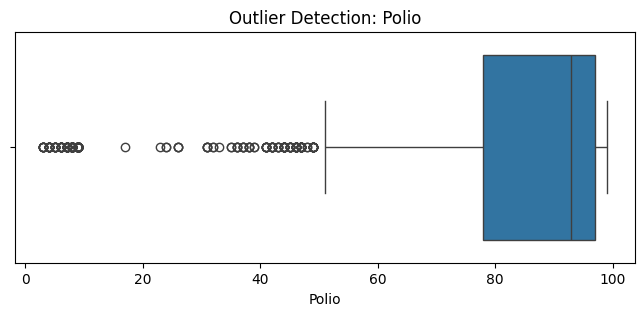

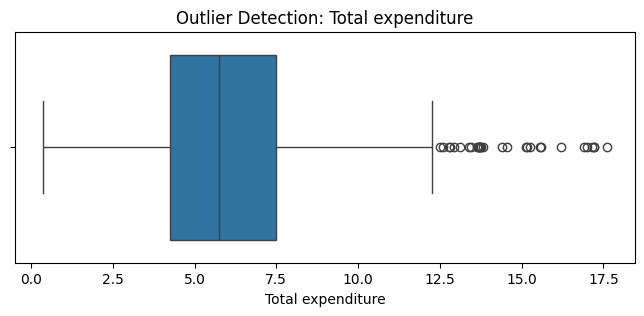

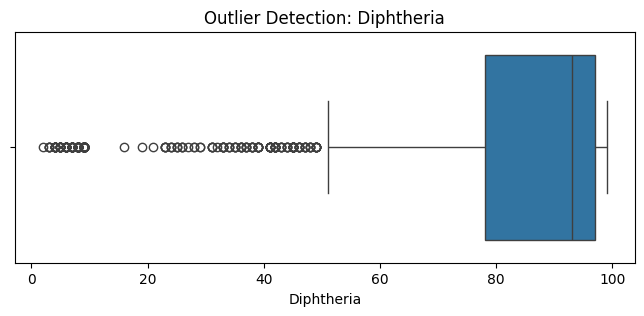

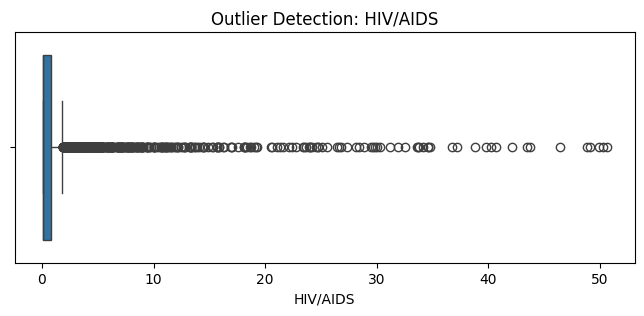

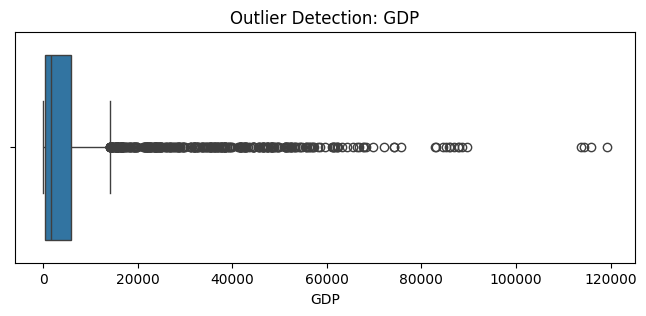

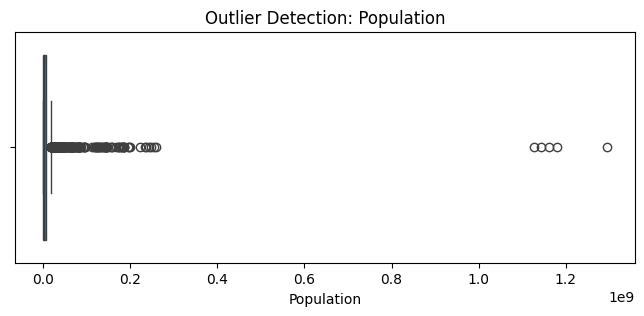

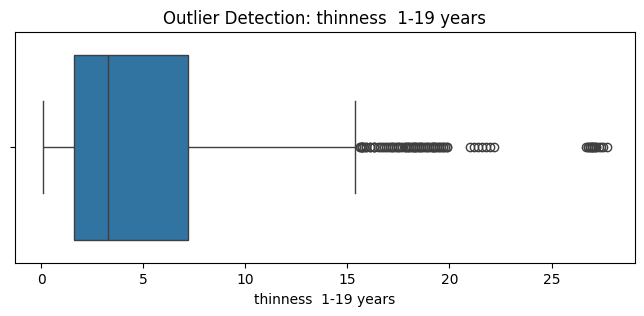

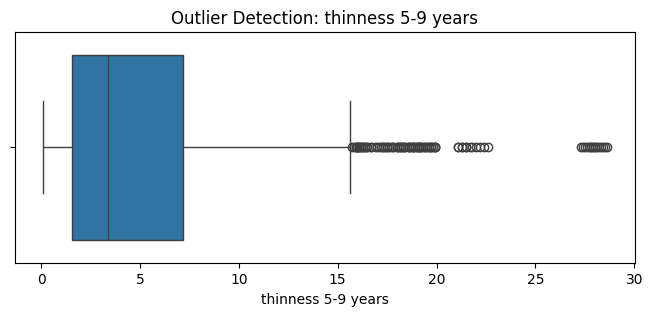

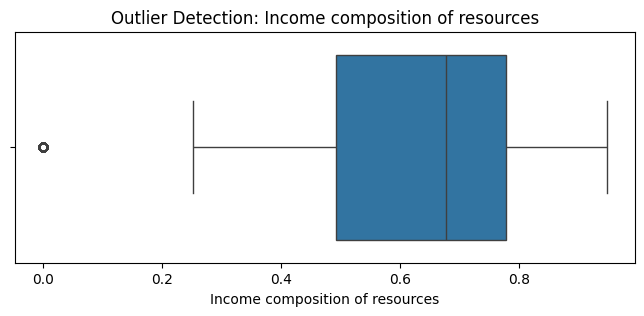

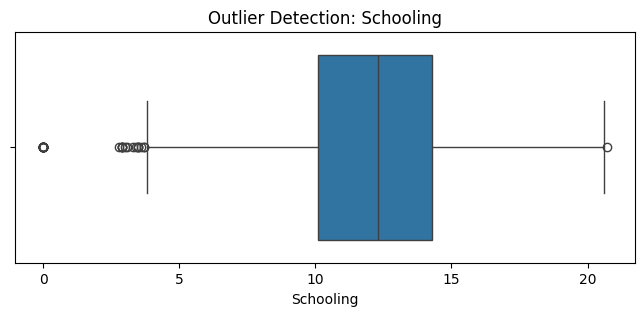

In [161]:
df_numeric = df.select_dtypes(include=np.number)

for col in df_numeric.columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df_numeric[col])
    plt.title("Outlier Detection: " + col)
    plt.show()

In [162]:
outlier_columns = [
    "GDP",
    "Population",
    "Adult Mortality",
    "infant deaths"
]

outlier_columns = [
    col for col in outlier_columns if col in df.columns
]

print("Features selected:", outlier_columns)

Features selected: ['GDP', 'Population', 'Adult Mortality', 'infant deaths']


In [163]:
df = pd.get_dummies(df, columns=["Status"], drop_first=True, dtype=int)

X = df.drop("Life expectancy", axis=1)
y = df["Life expectancy"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [164]:
Q1 = X_train[outlier_columns].quantile(0.25)
Q3 = X_train[outlier_columns].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limits:")
print(lower_limit)

print("\nUpper limits:")
print(upper_limit)

Lower limits:
GDP               -7.521816e+03
Population        -1.075939e+07
Adult Mortality   -1.570000e+02
infant deaths     -3.300000e+01
dtype: float64

Upper limits:
GDP                1.376136e+04
Population         1.850498e+07
Adult Mortality    4.590000e+02
infant deaths      5.500000e+01
dtype: float64


In [165]:
outlier_mask = (
    (X_train[outlier_columns] < lower_limit) |
    (X_train[outlier_columns] > upper_limit)
).any(axis=1)

X_train_clean = X_train.loc[~outlier_mask].copy()
y_train_clean = y_train.loc[~outlier_mask].copy()

print("Training rows before:", len(X_train))
print("Training rows after:", len(X_train_clean))
print("Rows removed:", outlier_mask.sum())

Training rows before: 2342
Training rows after: 1619
Rows removed: 723


In [166]:
X_test_clean = X_test.copy()

for col in outlier_columns:
    X_test_clean[col] = X_test_clean[col].clip(
        lower=lower_limit[col],
        upper=upper_limit[col]
    )

print("Training rows:", len(X_train_clean))
print("Testing rows:", len(X_test_clean))

Training rows: 1619
Testing rows: 586


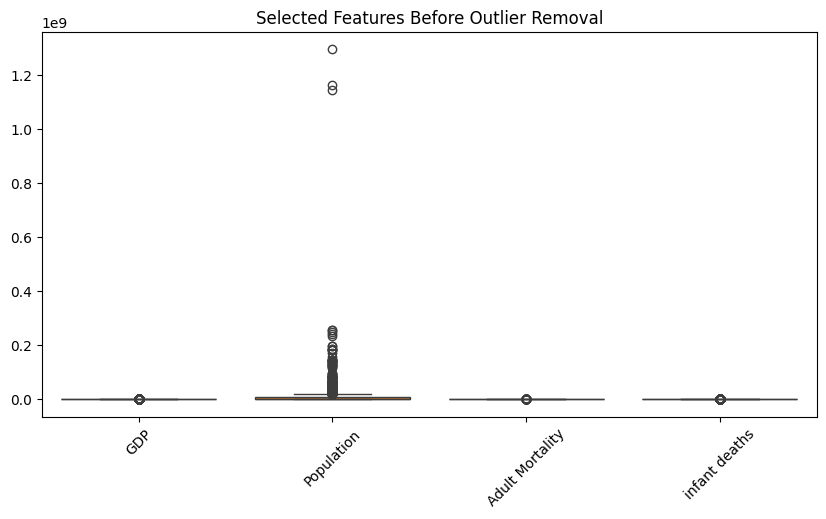

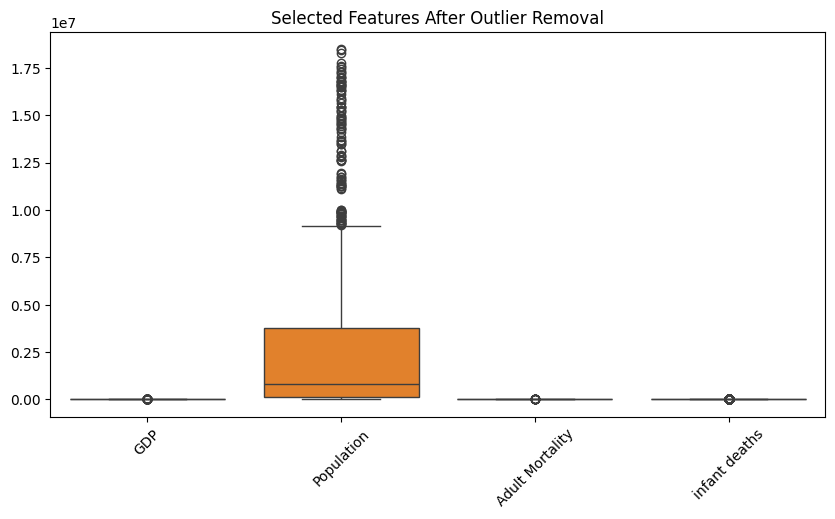

In [167]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=X_train[outlier_columns])
plt.title("Selected Features Before Outlier Removal")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(data=X_train_clean[outlier_columns])
plt.title("Selected Features After Outlier Removal")
plt.xticks(rotation=45)
plt.show()

In [168]:
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X.columns,
    index=X_test.index
)

In [169]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (2342, 20)
Testing data: (586, 20)


In [170]:
results = pd.DataFrame(columns=["Model", "R2", "MAE", "MSE", "RMSE"])

In [171]:
#Linear Regression

X_train_simple = X_train[["Schooling"]]
X_test_simple = X_test[["Schooling"]]

simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train)

simple_pred = simple_model.predict(X_test_simple)

In [172]:
simple_r2 = r2_score(y_test, simple_pred)
simple_mae = mean_absolute_error(y_test, simple_pred)
simple_mse = mean_squared_error(y_test, simple_pred)
simple_rmse = np.sqrt(simple_mse)

results.loc[len(results)] = [
    "Simple Linear Regression",
    simple_r2, simple_mae, simple_mse, simple_rmse
]

print("R2:", simple_r2)
print("MAE:", simple_mae)
print("MSE:", simple_mse)
print("RMSE:", simple_rmse)

R2: 0.5517373918768889
MAE: 4.639579605168194
MSE: 38.77444768625611
RMSE: 6.2269131747805915


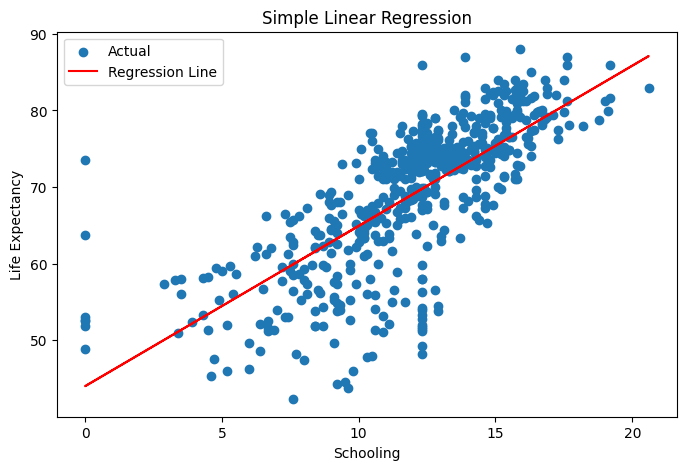

In [173]:
plt.figure(figsize=(8, 5))

plt.scatter(X_test_simple["Schooling"], y_test, label="Actual")

plt.plot(
    X_test_simple["Schooling"],
    simple_pred,
    color="red",
    label="Regression Line"
)

plt.xlabel("Schooling")
plt.ylabel("Life Expectancy")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()


In [174]:
# Multiple Linear Regression

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

linear_pred = linear_model.predict(X_test_scaled)

In [175]:
linear_r2 = r2_score(y_test, linear_pred)
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_mse = mean_squared_error(y_test, linear_pred)
linear_rmse = np.sqrt(linear_mse)

results.loc[len(results)] = [
    "Multiple Linear Regression",
    linear_r2, linear_mae, linear_mse, linear_rmse
]

print("R2:", linear_r2)
print("MAE:", linear_mae)
print("MSE:", linear_mse)
print("RMSE:", linear_rmse)

R2: 0.8194875321804442
MAE: 2.927326916023631
MSE: 15.614220578184097
RMSE: 3.9514833389733655


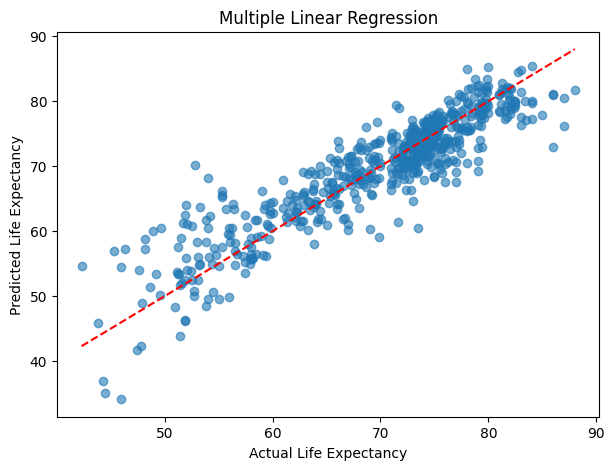

In [176]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, linear_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Life Expectancy")
plt.ylabel("Predicted Life Expectancy")
plt.title("Multiple Linear Regression")
plt.show()


In [177]:
# Polynomial linear regression

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

poly_pred = poly_model.predict(X_test_poly)

In [178]:
poly_r2 = r2_score(y_test, poly_pred)
poly_mae = mean_absolute_error(y_test, poly_pred)
poly_mse = mean_squared_error(y_test, poly_pred)
poly_rmse = np.sqrt(poly_mse)

results.loc[len(results)] = [
    "Polynomial Regression",
    poly_r2, poly_mae, poly_mse, poly_rmse
]

print("R2:", poly_r2)
print("MAE:", poly_mae)
print("MSE:", poly_mse)
print("RMSE:", poly_rmse)

R2: 0.8946429780005933
MAE: 2.059924416917218
MSE: 9.113319433446426
RMSE: 3.0188274931579686


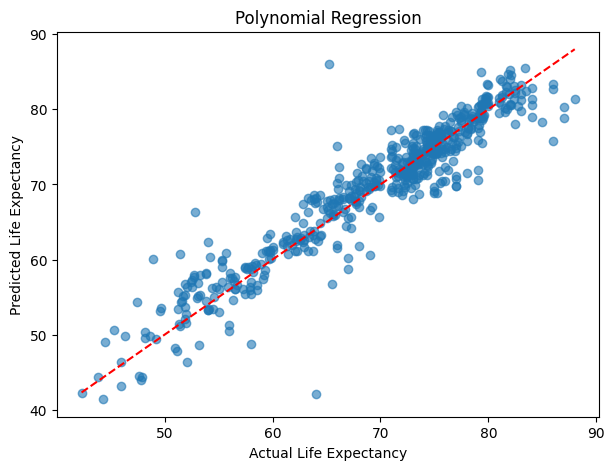

In [179]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, poly_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Life Expectancy")
plt.ylabel("Predicted Life Expectancy")
plt.title("Polynomial Regression")
plt.show()


In [180]:
# Ridge
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)

ridge_pred = ridge_model.predict(X_test_scaled)

In [181]:
ridge_r2 = r2_score(y_test, ridge_pred)
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)

results.loc[len(results)] = [
    "Ridge Regression",
    ridge_r2, ridge_mae, ridge_mse, ridge_rmse
]

print("R2:", ridge_r2)
print("MAE:", ridge_mae)
print("MSE:", ridge_mse)
print("RMSE:", ridge_rmse)


R2: 0.8192629736027598
MAE: 2.9268330318811775
MSE: 15.633644760940232
RMSE: 3.9539404093815365


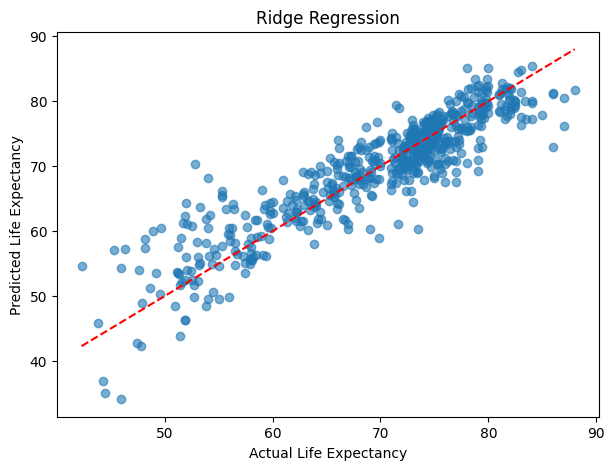

In [182]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, ridge_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Life Expectancy")
plt.ylabel("Predicted Life Expectancy")
plt.title("Ridge Regression")
plt.show()


In [183]:
# Lasso
lasso_model = Lasso(alpha=0.01, max_iter=20000)
lasso_model.fit(X_train_scaled, y_train)

lasso_pred = lasso_model.predict(X_test_scaled)

In [184]:
lasso_r2 = r2_score(y_test, lasso_pred)
lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_mse = mean_squared_error(y_test, lasso_pred)
lasso_rmse = np.sqrt(lasso_mse)

results.loc[len(results)] = [
    "Lasso Regression",
    lasso_r2, lasso_mae, lasso_mse, lasso_rmse
]

print("R2:", lasso_r2)
print("MAE:", lasso_mae)
print("MSE:", lasso_mse)
print("RMSE:", lasso_rmse)

R2: 0.8186738964403292
MAE: 2.928862419922643
MSE: 15.68459958341242
RMSE: 3.9603787171699145


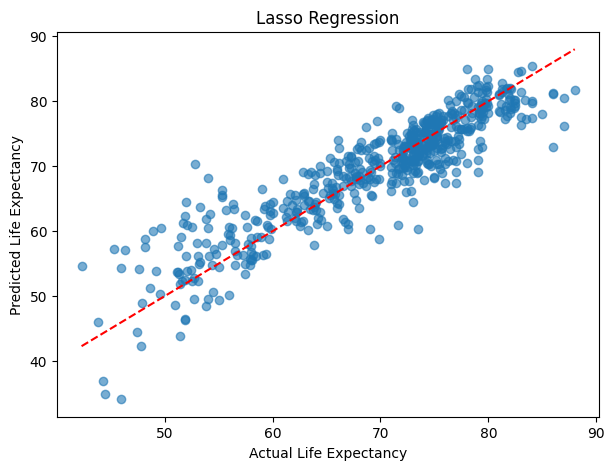

In [185]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, lasso_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Life Expectancy")
plt.ylabel("Predicted Life Expectancy")
plt.title("Lasso Regression")
plt.show()


In [186]:
# SVR
svr_model = SVR(kernel="rbf", C=10, epsilon=0.1)
svr_model.fit(X_train_scaled, y_train)

svr_pred = svr_model.predict(X_test_scaled)

In [187]:
svr_r2 = r2_score(y_test, svr_pred)
svr_mae = mean_absolute_error(y_test, svr_pred)
svr_mse = mean_squared_error(y_test, svr_pred)
svr_rmse = np.sqrt(svr_mse)

results.loc[len(results)] = [
    "SVR",
    svr_r2, svr_mae, svr_mse, svr_rmse
]

print("R2:", svr_r2)
print("MAE:", svr_mae)
print("MSE:", svr_mse)
print("RMSE:", svr_rmse)

R2: 0.9248347566937708
MAE: 1.589103861833915
MSE: 6.5017486214278675
RMSE: 2.5498526666119097


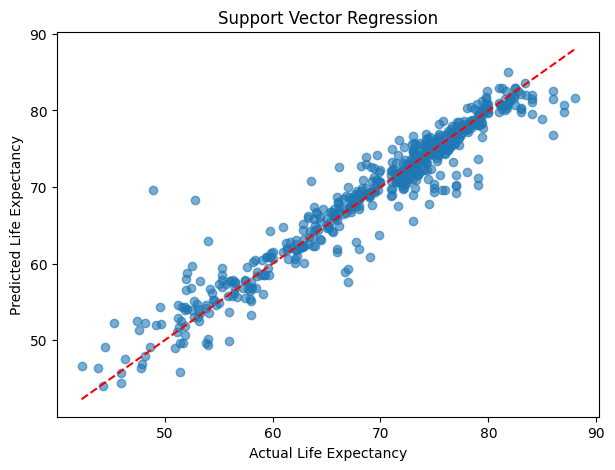

In [188]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, svr_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Life Expectancy")
plt.ylabel("Predicted Life Expectancy")
plt.title("Support Vector Regression")
plt.show()


In [189]:
# Decision Tree

dt_model = DecisionTreeRegressor(random_state=42)

dt_params = {
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

dt_grid = GridSearchCV(
    dt_model, dt_params, cv=5,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best Parameters:", dt_grid.best_params_)
print("Best CV RMSE:", -dt_grid.best_score_)

Best Parameters: {'max_depth': 15, 'min_samples_leaf': 2, 'min_samples_split': 5}
Best CV RMSE: 2.6676950576020624


In [190]:
# Predict using the tuned model
dt_best = dt_grid.best_estimator_
dt_pred = dt_best.predict(X_test)

# Evaluate the tuned model
print("Test R2:", round(r2_score(y_test, dt_pred), 4))
print("Test MAE:", round(mean_absolute_error(y_test, dt_pred), 4))
print("Test MSE:", round(mean_squared_error(y_test, dt_pred), 4))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, dt_pred)), 4))

Test R2: 0.9292
Test MAE: 1.5494
Test MSE: 6.1261
Test RMSE: 2.4751


In [191]:
# Random Forest
forest_model = RandomForestRegressor(
    n_estimators=100, random_state=42, n_jobs=-1
)

forest_model.fit(X_train, y_train)
forest_pred = forest_model.predict(X_test)

In [192]:
forest_r2 = r2_score(y_test, forest_pred)
forest_mae = mean_absolute_error(y_test, forest_pred)
forest_mse = mean_squared_error(y_test, forest_pred)
forest_rmse = np.sqrt(forest_mse)

results.loc[len(results)] = [
    "Random Forest",
    forest_r2, forest_mae, forest_mse, forest_rmse
]

print("R2:", forest_r2)
print("MAE:", forest_mae)
print("MSE:", forest_mse)
print("RMSE:", forest_rmse)

R2: 0.9677777631541155
MAE: 1.0452013651877154
MSE: 2.7872042286689416
RMSE: 1.66949220683085


In [193]:
# Bagging

bagging_model = BaggingRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

bagging_model.fit(X_train, y_train)
bagging_pred = bagging_model.predict(X_test)

In [194]:
bagging_r2 = r2_score(y_test, bagging_pred)
bagging_mae = mean_absolute_error(y_test, bagging_pred)
bagging_mse = mean_squared_error(y_test, bagging_pred)
bagging_rmse = np.sqrt(bagging_mse)

results.loc[len(results)] = [
    "Bagging Regression",
    bagging_r2, bagging_mae, bagging_mse, bagging_rmse
]

print("R2:", bagging_r2)
print("MAE:", bagging_mae)
print("MSE:", bagging_mse)
print("RMSE:", bagging_rmse)

R2: 0.9676363148213271
MAE: 1.0475580204778157
MSE: 2.7994394249146777
RMSE: 1.6731525408386043


In [195]:
X_glm_train = sm.add_constant(X_train_scaled, has_constant="add")
X_glm_test = sm.add_constant(X_test_scaled, has_constant="add")

In [196]:
glm_gaussian = sm.GLM(y_train, X_glm_train, family=sm.families.Gaussian()).fit()
glm_gaussian_pred = glm_gaussian.predict(X_glm_test)

In [197]:
glm_poisson = sm.GLM(y_train, X_glm_train, family=sm.families.Poisson()).fit()
glm_poisson_pred = glm_poisson.predict(X_glm_test)


In [198]:
glm_gamma = sm.GLM(y_train, X_glm_train, family=sm.families.Gamma(link=sm.families.links.Log())).fit()
glm_gamma_pred = glm_gamma.predict(X_glm_test)

In [199]:
glm_models = {
    "GLM Gaussian (Linear)": glm_gaussian_pred,
    "GLM Poisson": glm_poisson_pred,
    "GLM Gamma": glm_gamma_pred
}

for model_name, pred in glm_models.items():
    mse = mean_squared_error(y_test, pred)
    print("\n", model_name)
    print("R2:", round(r2_score(y_test, pred), 4))
    print("MAE:", round(mean_absolute_error(y_test, pred), 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(np.sqrt(mse), 4))

    results.loc[len(results)] = [
        model_name,
        r2_score(y_test, pred),
        mean_absolute_error(y_test, pred),
        mse,
        np.sqrt(mse)
    ]


 GLM Gaussian (Linear)
R2: 0.8195
MAE: 2.9273
MSE: 15.6142
RMSE: 3.9515

 GLM Poisson
R2: 0.8245
MAE: 2.9185
MSE: 15.1827
RMSE: 3.8965

 GLM Gamma
R2: 0.8237
MAE: 2.9342
MSE: 15.2497
RMSE: 3.9051


In [200]:
results = results.sort_values("R2", ascending=False).reset_index(drop=True)
print("\nUpdated model comparison:")
print(results.round(4))


Updated model comparison:
                         Model      R2     MAE      MSE    RMSE
0                Random Forest  0.9678  1.0452   2.7872  1.6695
1           Bagging Regression  0.9676  1.0476   2.7994  1.6732
2                          SVR  0.9248  1.5891   6.5017  2.5499
3        Polynomial Regression  0.8946  2.0599   9.1133  3.0188
4                  GLM Poisson  0.8245  2.9185  15.1827  3.8965
5                    GLM Gamma  0.8237  2.9342  15.2497  3.9051
6        GLM Gaussian (Linear)  0.8195  2.9273  15.6142  3.9515
7   Multiple Linear Regression  0.8195  2.9273  15.6142  3.9515
8             Ridge Regression  0.8193  2.9268  15.6336  3.9539
9             Lasso Regression  0.8187  2.9289  15.6846  3.9604
10    Simple Linear Regression  0.5517  4.6396  38.7744  6.2269


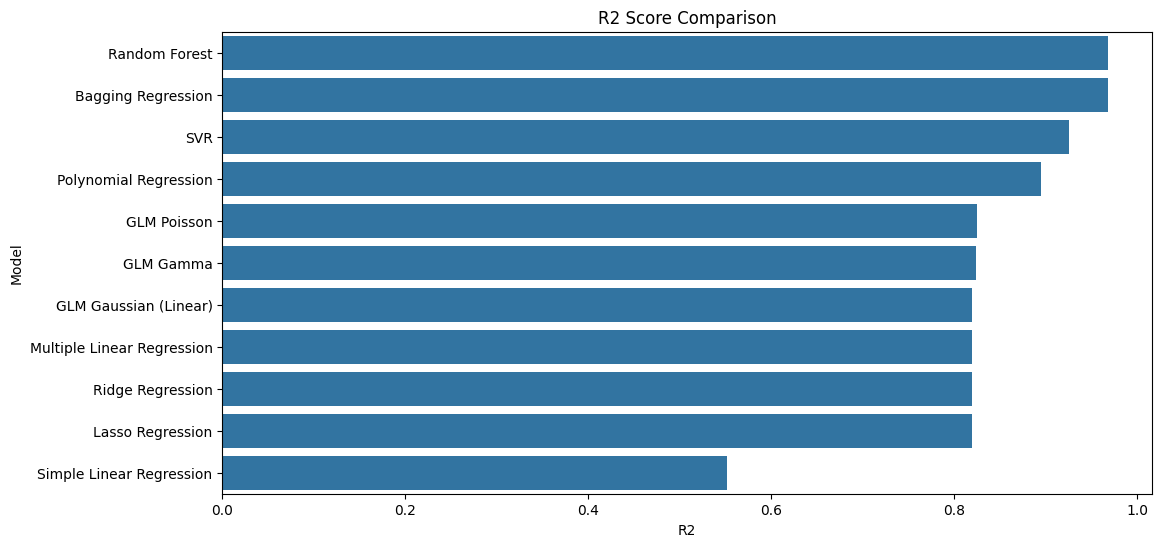

In [201]:
plt.figure(figsize=(12, 6))
sns.barplot(data=results, x="R2", y="Model")
plt.title("R2 Score Comparison")
plt.show()


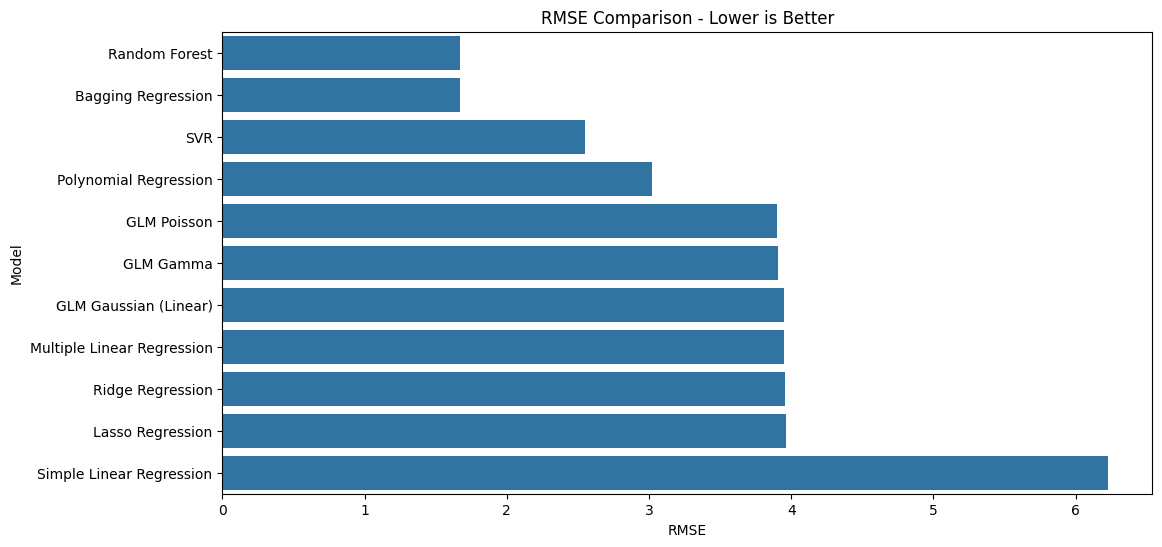

In [202]:
plt.figure(figsize=(12, 6))
sns.barplot(data=results, x="RMSE", y="Model")
plt.title("RMSE Comparison - Lower is Better")
plt.show()

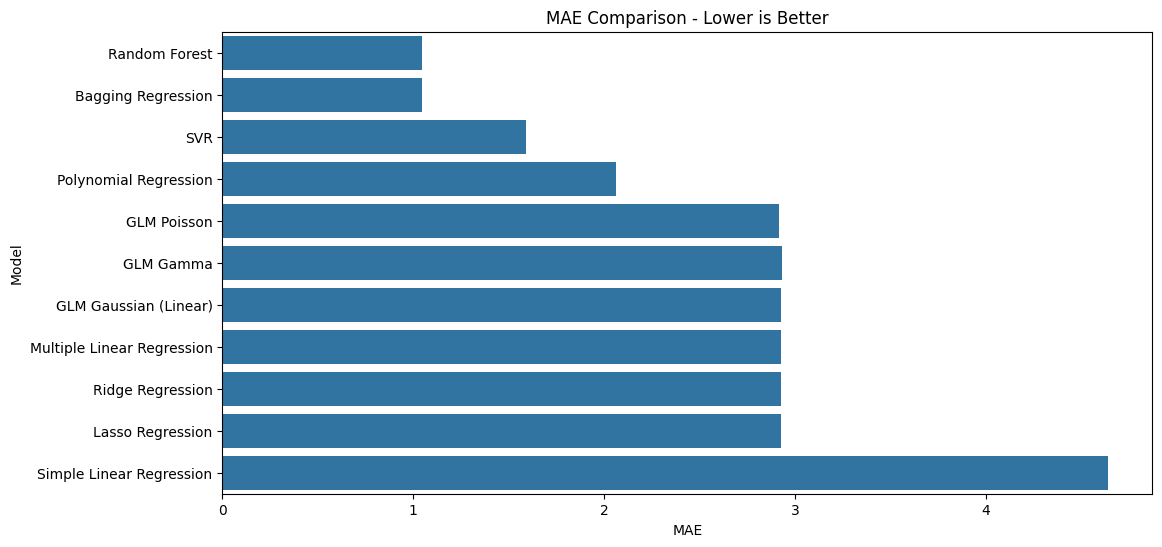

In [203]:
plt.figure(figsize=(12, 6))
sns.barplot(data=results, x="MAE", y="Model")
plt.title("MAE Comparison - Lower is Better")
plt.show()

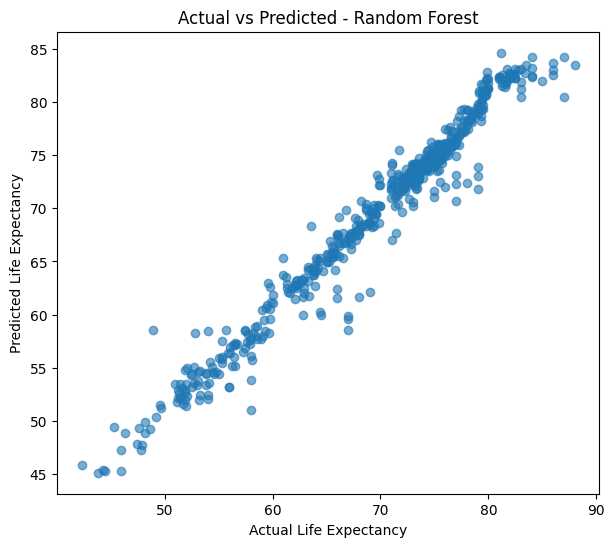

Best model: Random Forest
Model    Random Forest
R2            0.967778
MAE           1.045201
MSE           2.787204
RMSE          1.669492
Name: 0, dtype: object


In [204]:

best_model_name = results.loc[0, "Model"]

if best_model_name == "Simple Linear Regression":
    best_pred = simple_pred
elif best_model_name == "Multiple Linear Regression":
    best_pred = linear_pred
elif best_model_name == "Polynomial Regression":
    best_pred = poly_pred
elif best_model_name == "Ridge Regression":
    best_pred = ridge_pred
elif best_model_name == "Lasso Regression":
    best_pred = lasso_pred
elif best_model_name == "SVR":
    best_pred = svr_pred
elif best_model_name == "Decision Tree":
    best_pred = tree_pred
elif best_model_name == "Random Forest":
    best_pred = forest_pred
elif best_model_name == "Bagging Regression":
    best_pred = bagging_pred
elif best_model_name == "Extra Trees Regression":
    best_pred = extra_pred
else:
    best_pred = stack_pred

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred, alpha=0.6)

plt.xlabel("Actual Life Expectancy")
plt.ylabel("Predicted Life Expectancy")
plt.title("Actual vs Predicted - " + best_model_name)

plt.show()

print("Best model:", best_model_name)
print(results.iloc[0])


                            Feature  Importance
12                         HIV/AIDS    0.596054
17  Income composition of resources    0.172314
1                   Adult Mortality    0.124767
7                               BMI    0.017715
8                 under-five deaths    0.016408
18                        Schooling    0.010129
16               thinness 5-9 years    0.009721
3                           Alcohol    0.007665
0                              Year    0.007193
15             thinness  1-19 years    0.005278


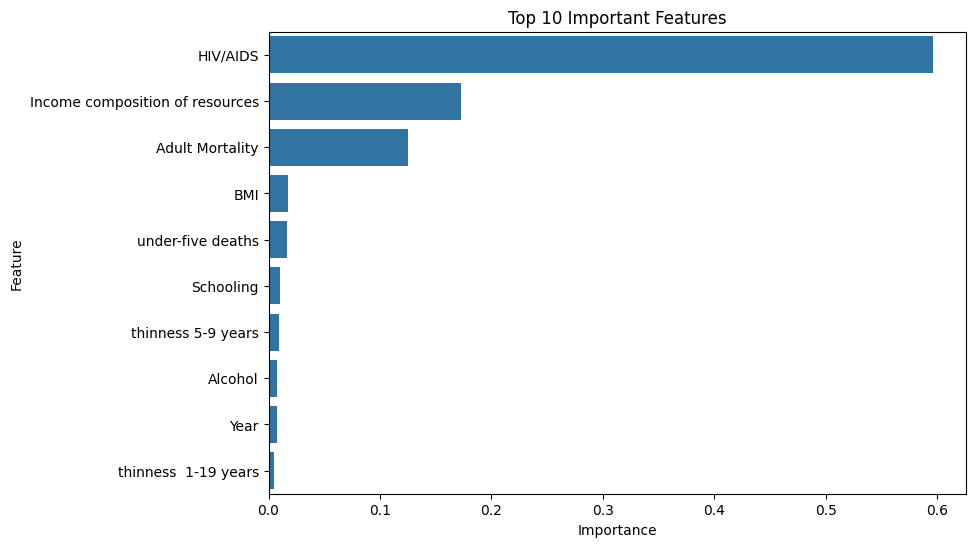

In [205]:

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": forest_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

print(importance.head(10))

plt.figure(figsize=(9, 6))
sns.barplot(data=importance.head(10), x="Importance", y="Feature")
plt.title("Top 10 Important Features")
plt.show()


In [206]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Models
models = {
    "Simple Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Multiple Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Polynomial Regression": Pipeline([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ]),

    "Lasso Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(max_iter=10000))
    ]),

    "SVR": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR(kernel="rbf"))
    ]),

    "Decision Tree": DecisionTreeRegressor(random_state=42),

    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ),

    "Bagging": BaggingRegressor(random_state=42, n_jobs=-1),

    "GLM Gaussian": Pipeline([
        ("scaler", StandardScaler()),
        ("model", __import__("sklearn.linear_model", fromlist=["TweedieRegressor"])
         .TweedieRegressor(power=0, link="identity", max_iter=10000))
    ]),

    "GLM Poisson": Pipeline([
        ("scaler", StandardScaler()),
        ("model", PoissonRegressor(max_iter=10000))
    ]),

    "GLM Gamma": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GammaRegressor(max_iter=10000))
    ])
}

results = []

for name, model in models.items():
    X_cv = X_train[["Schooling"]] if name == "Simple Linear Regression" else X_train

    scores = cross_val_score(
        model,
        X_cv,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Mean CV RMSE": -scores.mean(),
        "CV RMSE Std": scores.std()
    })

cv_results = pd.DataFrame(results)
cv_results = cv_results.sort_values("Mean CV RMSE").reset_index(drop=True)

print(cv_results.round(4))

                         Model  Mean CV RMSE  CV RMSE Std
0                Random Forest        1.9868       0.1272
1                      Bagging        2.1404       0.1360
2                Decision Tree        2.9416       0.0613
3        Polynomial Regression        3.3730       0.5098
4                          SVR        3.8188       0.3514
5   Multiple Linear Regression        4.1067       0.1805
6             Ridge Regression        4.1074       0.1746
7                  GLM Poisson        4.1146       0.1487
8             Lasso Regression        4.5527       0.2068
9                    GLM Gamma        4.6398       0.1855
10                GLM Gaussian        4.6661       0.1985
11    Simple Linear Regression        6.7251       0.4137
